# Module 4: Evaluation Metrics
Evaluating model to get more accurate predictions

In [3]:
import numpy as np
import pandas as pd

In [4]:
# load data
df = pd.read_csv("../data/course_lead_scoring_2026.csv")


df.head(10)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
5,referral,manufacturing,employed,africa,43841.0,3,5,0.77,1
6,NaN,education,employed,north_america,58738.0,3,9,0.78,1
7,paid_ads,technology,employed,north_america,95059.0,2,4,0.41,1
8,organic_search,healthcare,employed,asia,62565.0,3,6,0.52,1
9,referral,retail,student,asia,12000.0,2,2,0.35,0


## Data Preparation


- Check if the missing values are presented in the features.
- If there are missing values:
    - For categorical features, replace them with 'NA'
    - For numerical features, replace with with 0.0

- Split the data into 3 parts.

In [5]:
numerical_cols = df.select_dtypes(include='number').columns

categorical_cols = df.select_dtypes(include=['category', 'object']).columns

/tmp/ipykernel_19265/674020711.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['category', 'object']).columns


In [6]:
## calculate the before na for each
df[numerical_cols] = df[numerical_cols].fillna(0.0)
df[categorical_cols] = df[categorical_cols].fillna("NA")

# see if there's still any NA values
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [7]:
from sklearn.model_selection import train_test_split

# training 80%, testing 20%
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

# the 80% data is split: 75% pure model training, 25% model evaluation
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)


X_train = df_train.reset_index(drop=True)
X_val = df_val.reset_index(drop=True)
X_test = df_test.reset_index(drop=True)


y_train = X_train.converted.values
y_val = X_val.converted.values
y_test = X_test.converted.values

del X_train['converted']
del X_val['converted']
del X_test['converted']

## Question 1: ROC AUC feature importance



In [8]:
categorical_cols

Index(['lead_source', 'industry', 'employment_status', 'location'], dtype='str')

In [9]:
numerical_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']

In [10]:
from sklearn.metrics import roc_auc_score

auc_scores = {}
for num_col in numerical_cols:
    score = roc_auc_score(df_train['converted'], df_train[num_col])
    # add the score to the dictionary
    auc_scores[num_col] = score
    if (score < 0.5):
        X_train[num_col] = -X_train[num_col]

print(f"scores: {auc_scores},\n maximum auc: {max(auc_scores, key=auc_scores.get)
}:")

scores: {'annual_income': 0.6081977776250831, 'number_of_courses_viewed': 0.7229894623989618, 'interaction_count': 0.7649203047563227, 'lead_score': 0.7882254810906102},
 maximum auc: lead_score:


## Question 2: Training the model

In [11]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

# creating dicts from data
train_dicts = X_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

In [12]:
val_dicts = X_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)


test_dicts = X_test.to_dict(orient = 'records')
X_test = dv.transform(test_dicts)

In [13]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [ ]:
y_pred = model.predict_proba(X_val)[:, 1]

array([0.54472295, 0.79005207, 0.50977909, 0.52913949, 0.82072027,
       0.54246   , 0.50178717, 0.54698398, 0.82553299, 0.40583754,
       0.91301567, 0.33581825, 0.30789883, 0.42704803, 0.6219229 ,
       0.53665458, 0.41931937, 0.84087345, 0.79969125, 0.61790114,
       0.61625181, 0.68059931, 0.85605897, 0.8078487 , 0.62046017,
       0.45970722, 0.54556724, 0.41221393, 0.72714023, 0.46812079,
       0.77222191, 0.79043883, 0.61433884, 0.78549759, 0.49753426,
       0.66077291, 0.69804763, 0.76896543, 0.65657501, 0.64127911,
       0.66509115, 0.57942826, 0.67830946, 0.61186114, 0.86890227,
       0.4146967 , 0.84130129, 0.74229365, 0.68028539, 0.7189143 ,
       0.86417929, 0.64043375, 0.5424699 , 0.70225152, 0.27894903,
       0.70826494, 0.62310718, 0.47781771, 0.37914032, 0.69936035,
       0.52032869, 0.69977698, 0.75148939, 0.58087503, 0.47001802,
       0.56863492, 0.91297185, 0.79972028, 0.82206546, 0.36140197,
       0.66132404, 0.52330065, 0.79295471, 0.72068083, 0.71234

In [15]:
thresh = 0.5
convert_decision = (y_pred >= thresh)

(y_val == convert_decision).mean()

np.float64(0.651)

In [16]:
model_auc = roc_auc_score(y_val, y_pred)

model_auc

0.7318222288173319

## Question 3 & 4:

**Precision, Recall, and f1**

In [17]:
scores = []

recall_vals = []
precision_vals = []
f1_vals = []


thresholds = np.linspace(0.0, 1.0, 100)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = (tp / (tp + fp))
    recall = (tp / (tp + fn))

    if (precision == 0 and recall == 0):
        f1 = 0
    else:
        f1 = 2 * ( (precision * recall) / (precision + recall) ) 

    precision_vals.append(precision)
    recall_vals.append(recall)
    f1_vals.append(f1)
    scores.append((t, tp, fp, fn, tn))


/tmp/ipykernel_19265/3312839554.py:23: RuntimeWarning: invalid value encountered in scalar divide
  precision = (tp / (tp + fp))


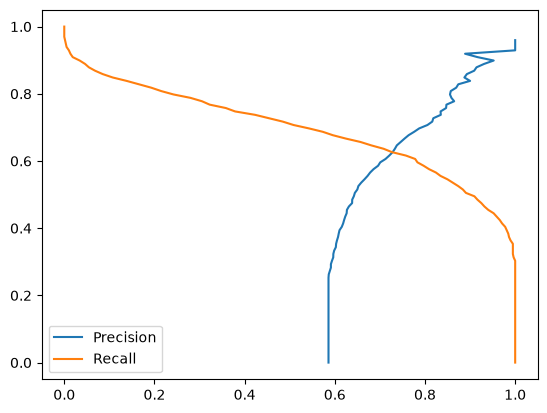

In [18]:
import matplotlib.pyplot as plt

plt.plot(precision_vals, thresholds, label='Precision')
plt.plot(recall_vals, thresholds, label='Recall')
plt.legend()

In [ ]:
# threshold at maximim f1 score
thresholds[f1_vals.index(max(f1_vals))]


np.float64(0.42424242424242425)

## Question 5: 5-Fold CV

In [53]:
def train(X_train, y_train, C):
    dv = DictVectorizer(sparse=False)

    # creating dicts from data
    train_dicts = X_train[categorical_cols + numerical_cols].to_dict(orient='records')
    X_train = dv.fit_transform(train_dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model


In [54]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
std_vals = {}

for C in tqdm([1.0, 0.000001, 0.001 ]):
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_q5 = df_full_train.iloc[train_idx]
        df_val_q5 = df_full_train.iloc[val_idx]

        y_train_q5 = df_train_q5.converted.values
        y_val_q5 = df_val_q5.converted.values

        dv_q5, model_q5 = train(df_train_q5, y_train_q5, C)

        dicts = df_val_q5[categorical_cols + numerical_cols].to_dict(orient='records')

        X = dv_q5.transform(dicts)
        y_pred_q5 = model_q5.predict_proba(X)[:, 1]

        auc_q5 = roc_auc_score(y_val_q5, y_pred_q5)
        scores.append(auc_q5)

    std_vals[C] = np.std(scores)


  0%|          | 0/3 [00:00<?, ?it/s]

In [55]:
std_vals

{1.0: np.float64(0.006853233151022138),
 1e-06: np.float64(0.018669799234831475),
 0.001: np.float64(0.009996375455700753)}